1. ¿Cuántos caracteres tienen las contraseñas?
2. ¿Qué tipos de caracteres usan?
3. ¿Cuántos tipos de caracteres combinan?
4. ¿Qué patrones se repiten?

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
COLOR = '#252850'

rockyou = pd.read_parquet("../data/processed/rockyou_limpio.parquet")
s = rockyou["password"]
rockyou["longitud"] = s.str.len()

print(f"Contraseñas cargadas: {len(rockyou):,}")

Contraseñas cargadas: 14,343,462


> **Nota metodológica:** la versión pública de RockYou contiene cada contraseña **una sola vez**
> (14,3 millones de contraseñas distintas), ordenadas por popularidad, pero sin indicar cuántas
> personas usaron cada una. Por eso, los porcentajes de este análisis describen las
> **contraseñas distintas**, no a los usuarios. 

1. ¿Cuántos caracteres tienen las contraseñas?


In [7]:
rockyou["longitud"].describe().round(2)

count    14343462.00
mean            8.74
std             2.42
min             1.00
25%             7.00
50%             8.00
75%            10.00
max            64.00
Name: longitud, dtype: float64

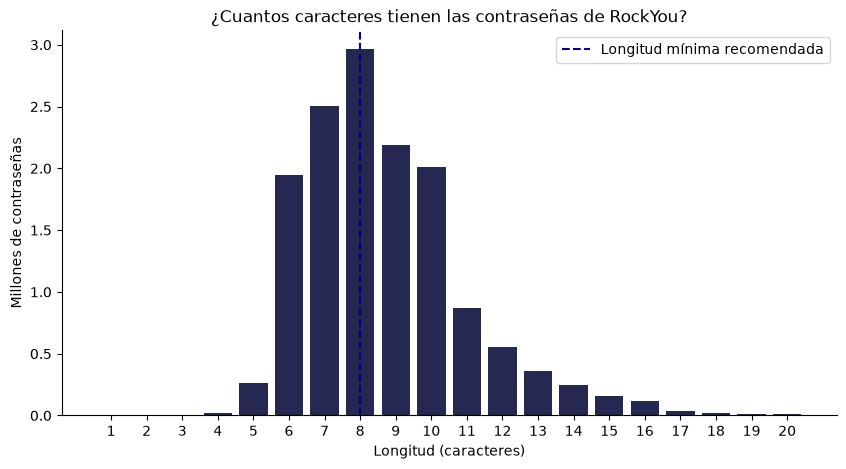

In [10]:
conteo = rockyou["longitud"].value_counts().sort_index()
conteo = conteo[conteo.index <= 20]

plt.bar(conteo.index, conteo.values / 1_000_000, color=COLOR)
plt.axvline(8, color="#00008B", linestyle="--", label="Longitud mínima recomendada")
plt.title("¿Cuantos caracteres tienen las contraseñas de RockYou?")
plt.xlabel("Longitud (caracteres)")
plt.ylabel("Millones de contraseñas")
plt.xticks(range(1, 21))
plt.legend()
plt.savefig("../docs/figuras/01_longitud_rockyou.png", dpi=150, bbox_inches="tight")

In [12]:
print(f"8 o menos: {(rockyou['longitud'] <= 8).mean():.1%}")
print(f"12 o más:  {(rockyou['longitud'] >= 12).mean():.1%}")

8 o menos: 53.7%
12 o más:  10.9%


2. ¿Qué tipos de caracteres usan?


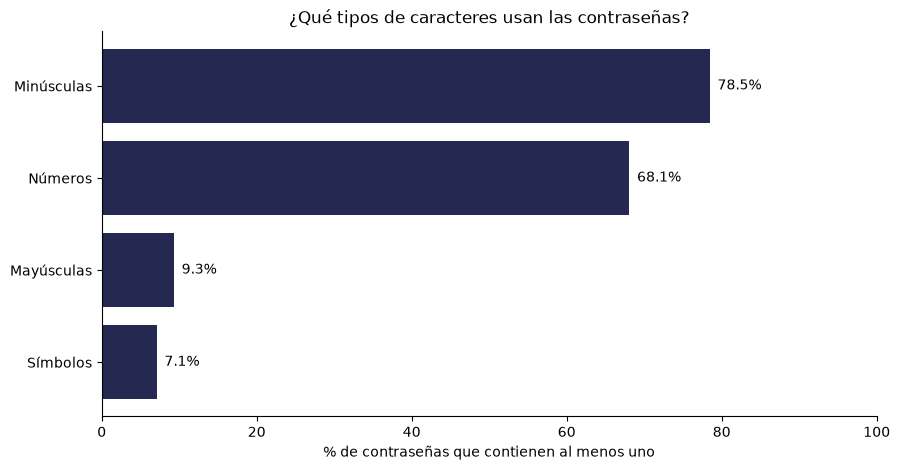

In [13]:
tipos = pd.DataFrame({
    "Minúsculas": s.str.contains(r"[a-z]"),
    "Números": s.str.contains(r"[0-9]"),
    "Mayúsculas": s.str.contains(r"[A-Z]"),
    "Símbolos": s.str.contains(r"[^a-zA-Z0-9]"),
})

porcentaje = tipos.mean().sort_values() * 100

plt.barh(porcentaje.index, porcentaje.values, color=COLOR)
plt.title("¿Qué tipos de caracteres usan las contraseñas?")
plt.xlabel("% de contraseñas que contienen al menos uno")
for i, v in enumerate(porcentaje.values):
    plt.text(v + 1, i, f"{v:.1f}%", va="center")
plt.xlim(0, 100)
plt.savefig("../docs/figuras/02_tipos_caracteres.png", dpi=150, bbox_inches="tight")
plt.show()

3. ¿Cuántos tipos de caracteres combinan?

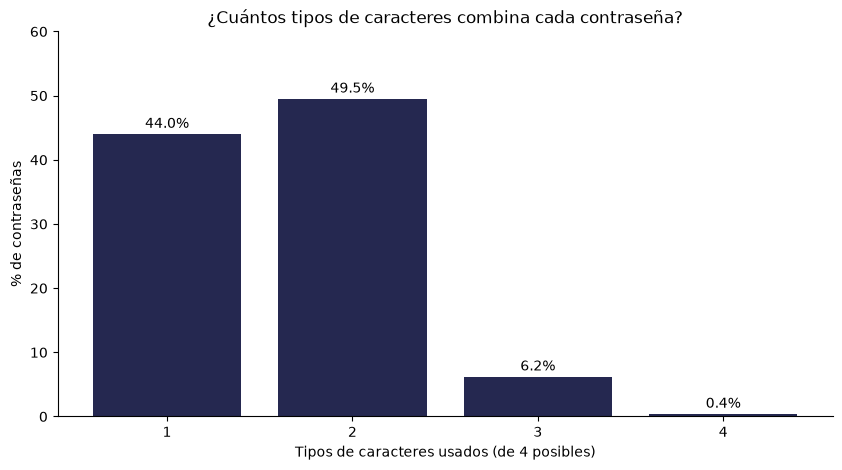

In [14]:
cantidad = tipos.sum(axis=1)
dist = cantidad.value_counts(normalize=True).sort_index() * 100

plt.bar(dist.index.astype(str), dist.values, color=COLOR)
plt.title("¿Cuántos tipos de caracteres combina cada contraseña?")
plt.xlabel("Tipos de caracteres usados (de 4 posibles)")
plt.ylabel("% de contraseñas")
for i, v in enumerate(dist.values):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.ylim(0, 60)
plt.savefig("../docs/figuras/03_cantidad_tipos.png", dpi=150, bbox_inches="tight")
plt.show()

4. ¿Qué patrones se repiten?

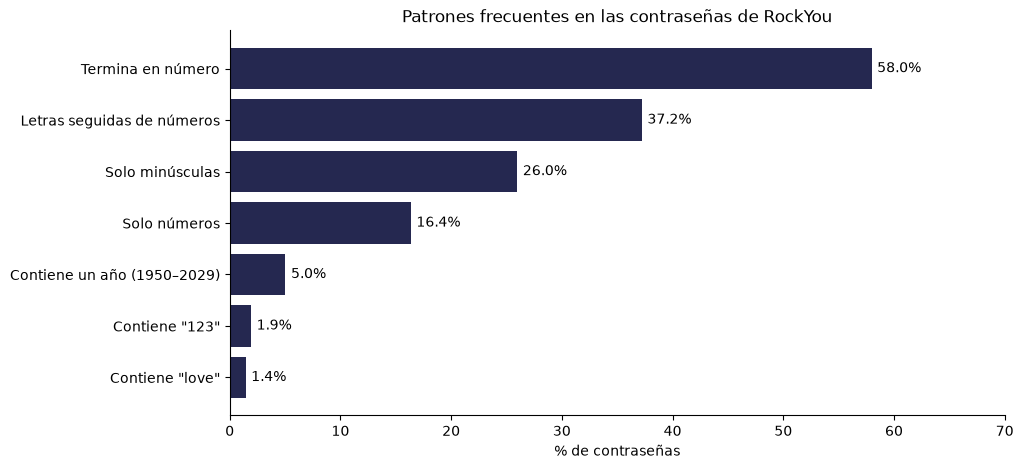

In [15]:
patrones = pd.Series({
    "Termina en número": s.str.contains(r"[0-9]$").mean(),
    "Letras seguidas de números": s.str.fullmatch(r"[a-zA-Z]+[0-9]+").mean(),
    "Solo minúsculas": s.str.fullmatch(r"[a-z]+").mean(),
    "Solo números": s.str.fullmatch(r"[0-9]+").mean(),
    "Contiene un año (1950–2029)": s.str.contains(r"(?:19[5-9][0-9]|20[0-2][0-9])").mean(),
    "Contiene \"123\"": s.str.contains("123", regex=False).mean(),
    "Contiene \"love\"": s.str.contains("love", case=False, regex=False).mean(),
}).sort_values() * 100

plt.barh(patrones.index, patrones.values, color=COLOR)
plt.title("Patrones frecuentes en las contraseñas de RockYou")
plt.xlabel("% de contraseñas")
for i, v in enumerate(patrones.values):
    plt.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.xlim(0, 70)
plt.savefig("../docs/figuras/04_patrones.png", dpi=150, bbox_inches="tight")
plt.show()

las 20 contrasenas mas comunes

In [17]:
rockyou.head(20)[["ranking", "password"]].style.hide(axis="index")

ranking,password
1,123456
2,12345
3,123456789
4,password
5,iloveyou
6,princess
7,1234567
8,rockyou
9,12345678
10,abc123
